<a href="https://colab.research.google.com/github/Affouka12/Entrainement-du-mod-le-de-cartographie-des-eaux-de-surface-v2/blob/main/Entrainement%20du%20mod%C3%A8le%20de%20cartographie%20des%20eaux%20de%20surface.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
"""
Cartographie des eaux de surface en CÔTE D'IVOIRE - Sentinel-1 + U-Net (encodeur ResNet50 pré-entraîné)
Version 2 : adaptée au contexte ivoirien

Adaptations Côte d'Ivoire
  - 8 zones d'étude : lagunes (Ébrié, Aby, Grand-Lahou), lacs de barrage (Ayamé, Taabo, Kossou, Buyo)
    et savane nord (Korhogo : retenues, bas-fonds, riziculture)
  - Fuseau UTM choisi automatiquement par zone (29N à l'ouest de -6°, 30N à l'est) -> EPSG:32629 / 32630
  - Dates d'entraînement réparties sur les saisons ivoiriennes (grande/petite saison sèche et des pluies)
  - Étiquettes S2 : MNDWI + NIR bas + pente < 15° (limite les ombres de relief / forêt)
  - Zones de TEST totalement exclues de l'entraînement (Grand-Lahou, Lac de Buyo) => F1 de généralisation honnête
  - Suivi temporel : journal CSV des surfaces en eau à chaque exécution quasi temps réel

Utilisation : copier chaque bloc "# %%" dans une cellule Google Colab (GPU T4 : Exécution > Modifier le type).
Le F1 = 0.92 est un OBJECTIF : il se mesure (cellule 8), il ne se garantit pas.
"""


'\nCartographie des eaux de surface en CÔTE D\'IVOIRE - Sentinel-1 + U-Net (encodeur ResNet50 pré-entraîné)\nVersion 2 : adaptée au contexte ivoirien\n\nAdaptations Côte d\'Ivoire\n  - 8 zones d\'étude : lagunes (Ébrié, Aby, Grand-Lahou), lacs de barrage (Ayamé, Taabo, Kossou, Buyo)\n    et savane nord (Korhogo : retenues, bas-fonds, riziculture)\n  - Fuseau UTM choisi automatiquement par zone (29N à l\'ouest de -6°, 30N à l\'est) -> EPSG:32629 / 32630\n  - Dates d\'entraînement réparties sur les saisons ivoiriennes (grande/petite saison sèche et des pluies)\n  - Étiquettes S2 : MNDWI + NIR bas + pente < 15° (limite les ombres de relief / forêt)\n  - Zones de TEST totalement exclues de l\'entraînement (Grand-Lahou, Lac de Buyo) => F1 de généralisation honnête\n  - Suivi temporel : journal CSV des surfaces en eau à chaque exécution quasi temps réel\n\nUtilisation : copier chaque bloc "# %%" dans une cellule Google Colab (GPU T4 : Exécution > Modifier le type).\nLe F1 = 0.92 est un OBJEC

In [2]:
# [1] Installation et Drive
!pip -q install earthengine-api rasterio pyproj matplotlib
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/eau_ci_s1"
except Exception:
    OUT_DIR = "./eau_ci_s1"
os.makedirs(OUT_DIR, exist_ok=True)

Mounted at /content/drive


In [3]:

# [2] Imports & configuration
import io, json, random, csv, datetime as dt
from functools import lru_cache
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import numpy.lib.recfunctions as rfn
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import ee, rasterio
from rasterio.transform import from_origin
from pyproj import Transformer

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

GEE_PROJECT = "ee-francktanoh17"        # <-- à remplacer


In [4]:
# Zones d'étude (lon_min, lat_min, lon_max, lat_max). Emprises APPROXIMATIVES : vérifiez-les sur la carte GEE.
AOIS = {
    "Ebrie_Abidjan": (-4.40, 5.15, -3.85, 5.45),   # lagune Ébrié, Abidjan (ville, mangroves, jacinthe d'eau)
    "Aby_Assinie":   (-3.45, 5.05, -2.95, 5.30),   # lagune Aby / Tendo / Ehy
    "Grand_Lahou":   (-5.25, 5.08, -4.75, 5.28),   # lagune Tagba / Grand-Lahou, embouchure du Bandama
    "Lac_Ayame":     (-3.35, 5.55, -3.10, 5.80),   # barrage d'Ayamé (Bia)
    "Lac_Taabo":     (-5.25, 6.15, -5.00, 6.40),   # barrage de Taabo (Bandama)
    "Lac_Kossou":    (-5.70, 6.95, -5.25, 7.55),   # barrage de Kossou (Bandama)
    "Lac_Buyo":      (-7.25, 6.20, -6.85, 6.65),   # barrage de Buyo (Sassandra) - fuseau 29N
    "Korhogo_nord":  (-5.85, 9.30, -5.40, 9.65),   # savane : retenues agropastorales, bas-fonds, rizières
}
TEST_AOIS = ["Grand_Lahou", "Lac_Buyo"]  # jamais vues à l'entraînement


In [5]:
# Saisons ivoiriennes (sud) : grande saison sèche déc-mars | grande saison des pluies avr-juil |
# petite saison sèche août-sept | petite saison des pluies oct-nov. Nord : sèche nov-avr, pluies mai-oct.
TRAIN_DATES = ["2025-01-25", "2025-03-05", "2025-06-20", "2025-08-15",
               "2025-10-25", "2025-12-20", "2026-02-15", "2026-08-15"]
S1_HALF_WINDOW = 6          # S1 : date ± 6 jours
S2_HALF_WINDOW = 20         # S2 : date ± 20 jours (nuages fréquents)
MNDWI_T = 0.1
MIN_VALID_FRAC = 0.5
MAX_TILES_PER_AOI_DATE = 60
KEEP_DRY_TILE_PROB = 0.15   # on garde toutes les tuiles avec eau, et 15 % des tuiles sans eau
SCALE, TILE = 10, 256
N_CH = 4                    # VV, VH, VV-VH, pente
BATCH = 8
EPOCHS_STAGE1, EPOCHS_STAGE2 = 12, 60
USE_PRETRAINED = True       # False -> U-Net entraîné depuis zéro
CKPT = os.path.join(OUT_DIR, "unet_s1_water_ci.keras")
META = os.path.join(OUT_DIR, "unet_s1_water_ci_meta.json")

ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)


In [6]:
# [3] Prétraitement Sentinel-1 + étiquettes (GEE)
def s1_features(aoi, start, end):
    """[VV, VH, VV-VH, pente] normalisés + masque de validité S1.
    COPERNICUS/S1_GRD : orbites précises, bruit thermique retiré, calibration sigma0, correction de terrain, dB.
    Ajouts ici : masque d'angle d'incidence, filtre speckle, médiane temporelle, normalisation."""
    col = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(aoi).filterDate(start, end)
           .filter(ee.Filter.eq("instrumentMode", "IW"))
           .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
           .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))

    def prep(img):
        ang = img.select("angle")
        x = img.select(["VV", "VH"]).updateMask(ang.gt(31).And(ang.lt(45)))
        x = x.focalMedian(30, "circle", "meters")
        return x.copyProperties(img, ["system:time_start"])

    comp = col.map(prep).median()
    valid = comp.select("VV").mask().And(comp.select("VH").mask()).rename("S1VALID")
    vv = comp.select("VV").clamp(-30, 0); vh = comp.select("VH").clamp(-35, -5)
    feats = ee.Image.cat([
        vv.add(30).divide(30).rename("VV"),
        vh.add(35).divide(30).rename("VH"),
        vv.subtract(vh).clamp(0, 25).divide(25).rename("VVVH"),
        ee.Terrain.slope(ee.Image("USGS/SRTMGL1_003")).clamp(0, 30).divide(30).rename("SLOPE")]).unmask(0.5)
    return feats, valid


def s2_water_label(aoi, start, end):
    """Étiquette eau : MNDWI > seuil, NIR bas, pente < 15° ; nuages/ombres masqués (SCL)."""
    def mask(img):
        scl = img.select("SCL")
        return img.updateMask(scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)))
    s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi).filterDate(start, end)
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 70)).map(mask))
    med = s2.median()
    mndwi = med.normalizedDifference(["B3", "B11"])
    slope = ee.Terrain.slope(ee.Image("USGS/SRTMGL1_003"))
    water = mndwi.gt(MNDWI_T).And(med.select("B8").lt(2000)).And(slope.lt(15))
    return water.unmask(0).rename("LABEL"), mndwi.mask().unmask(0).rename("LVALID")


def training_image(geom, date_str):
    d = dt.date.fromisoformat(date_str); td = dt.timedelta
    feats, s1v = s1_features(geom, str(d - td(days=S1_HALF_WINDOW)), str(d + td(days=S1_HALF_WINDOW)))
    lab, lv = s2_water_label(geom, str(d - td(days=S2_HALF_WINDOW)), str(d + td(days=S2_HALF_WINDOW)))
    return ee.Image.cat([feats, lab, lv.And(s1v).rename("VALID")]).toFloat()   # 4 entrées + LABEL + VALID


In [7]:
# [4] Grille, fuseau UTM automatique, téléchargement
def epsg_for(bbox):
    """Fuseau UTM nord de la zone : 32629 (lon < -6°) ou 32630 (lon entre -6° et 0°)."""
    return 32600 + int((((bbox[0] + bbox[2]) / 2) + 180) // 6) + 1

@lru_cache(None)
def _tr(epsg): return Transformer.from_crs(4326, epsg, always_xy=True)

def bbox_utm(bbox, epsg):
    x0, y0 = _tr(epsg).transform(bbox[0], bbox[1]); x1, y1 = _tr(epsg).transform(bbox[2], bbox[3])
    return min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1)

def fetch(image, x0, y0, w, h, epsg):
    raw = ee.data.computePixels({
        "expression": image, "fileFormat": "NPY",
        "grid": {"dimensions": {"width": w, "height": h},
                 "affineTransform": {"scaleX": SCALE, "shearX": 0, "translateX": x0,
                                     "shearY": 0, "scaleY": -SCALE, "translateY": y0},
                 "crsCode": f"EPSG:{epsg}"}})
    return np.nan_to_num(rfn.structured_to_unstructured(np.load(io.BytesIO(raw))).astype(np.float32))

def tile_origins(bbox, epsg, tile_px=TILE):
    xmin, ymin, xmax, ymax = bbox_utm(bbox, epsg); step = tile_px * SCALE
    xs = np.arange(xmin, xmax - step, step); ys = np.arange(ymax, ymin + step, -step)
    return [(float(x), float(y), i, j) for j, y in enumerate(ys) for i, x in enumerate(xs)]


In [8]:
# float16 / uint8 pour économiser la RAM de Colab
X_list, Y_list, G_list, A_list = [], [], [], []
for name, bbox in AOIS.items():
    epsg, geom = epsg_for(bbox), ee.Geometry.Rectangle(bbox)
    for date_str in TRAIN_DATES:
        img = training_image(geom, date_str)
        origins = tile_origins(bbox, epsg); random.shuffle(origins)
        origins = origins[:MAX_TILES_PER_AOI_DATE * 2]

        def job(o):
            x0, y0, i, j = o
            try:
                a = fetch(img, x0, y0, TILE, TILE, epsg)
                if a.shape[:2] != (TILE, TILE) or a[..., 5].mean() < MIN_VALID_FRAC:
                    return None
                wf = (a[..., 4] * a[..., 5]).sum() / max(a[..., 5].sum(), 1)
                if wf < 0.005 and random.random() > KEEP_DRY_TILE_PROB:
                    return None
                return a, (name, i // 4, j // 4)
            except Exception:
                return None

        with ThreadPoolExecutor(8) as ex:
            res = [r for r in ex.map(job, origins) if r is not None][:MAX_TILES_PER_AOI_DATE]
        for a, g in res:
            X_list.append(a[..., :4].astype(np.float16)); Y_list.append(a[..., 4:6].astype(np.uint8))
            G_list.append(g); A_list.append(name)
        print(f"{name:14s} {date_str}: {len(res)} tuiles")

X, Y, A = np.stack(X_list), np.stack(Y_list), np.array(A_list)
del X_list, Y_list
print("Total :", X.shape, "| part d'eau (pixels valides) :", float((Y[..., 0] * Y[..., 1]).sum() / Y[..., 1].sum()))


Ebrie_Abidjan  2025-01-25: 60 tuiles
Ebrie_Abidjan  2025-03-05: 54 tuiles
Ebrie_Abidjan  2025-06-20: 48 tuiles
Ebrie_Abidjan  2025-08-15: 58 tuiles
Ebrie_Abidjan  2025-10-25: 60 tuiles
Ebrie_Abidjan  2025-12-20: 60 tuiles
Ebrie_Abidjan  2026-02-15: 60 tuiles
Ebrie_Abidjan  2026-08-15: 54 tuiles
Aby_Assinie    2025-01-25: 60 tuiles
Aby_Assinie    2025-03-05: 60 tuiles
Aby_Assinie    2025-06-20: 60 tuiles
Aby_Assinie    2025-08-15: 20 tuiles
Aby_Assinie    2025-10-25: 60 tuiles
Aby_Assinie    2025-12-20: 60 tuiles
Aby_Assinie    2026-02-15: 60 tuiles
Aby_Assinie    2026-08-15: 14 tuiles
Grand_Lahou    2025-01-25: 60 tuiles
Grand_Lahou    2025-03-05: 60 tuiles
Grand_Lahou    2025-06-20: 60 tuiles


Grand_Lahou    2025-08-15: 56 tuiles
Grand_Lahou    2025-10-25: 60 tuiles
Grand_Lahou    2025-12-20: 60 tuiles
Grand_Lahou    2026-02-15: 60 tuiles
Grand_Lahou    2026-08-15: 52 tuiles
Lac_Ayame      2025-01-25: 44 tuiles
Lac_Ayame      2025-03-05: 41 tuiles
Lac_Ayame      2025-06-20: 25 tuiles
Lac_Ayame      2025-08-15: 0 tuiles
Lac_Ayame      2025-10-25: 57 tuiles
Lac_Ayame      2025-12-20: 55 tuiles
Lac_Ayame      2026-02-15: 50 tuiles
Lac_Ayame      2026-08-15: 0 tuiles
Lac_Taabo      2025-01-25: 37 tuiles
Lac_Taabo      2025-03-05: 33 tuiles
Lac_Taabo      2025-06-20: 29 tuiles
Lac_Taabo      2025-08-15: 0 tuiles
Lac_Taabo      2025-10-25: 45 tuiles
Lac_Taabo      2025-12-20: 38 tuiles
Lac_Taabo      2026-02-15: 35 tuiles
Lac_Taabo      2026-08-15: 21 tuiles
Lac_Kossou     2025-01-25: 38 tuiles
Lac_Kossou     2025-03-05: 40 tuiles
Lac_Kossou     2025-06-20: 25 tuiles
Lac_Kossou     2025-08-15: 0 tuiles
Lac_Kossou     2025-10-25: 38 tuiles
Lac_Kossou     2025-12-20: 50 tuiles


Lac_Kossou     2026-02-15: 42 tuiles
Lac_Kossou     2026-08-15: 35 tuiles


Lac_Buyo       2025-01-25: 60 tuiles
Lac_Buyo       2025-03-05: 45 tuiles
Lac_Buyo       2025-06-20: 11 tuiles
Lac_Buyo       2025-08-15: 0 tuiles
Lac_Buyo       2025-10-25: 60 tuiles
Lac_Buyo       2025-12-20: 60 tuiles
Lac_Buyo       2026-02-15: 60 tuiles
Lac_Buyo       2026-08-15: 45 tuiles
Korhogo_nord   2025-01-25: 16 tuiles
Korhogo_nord   2025-03-05: 19 tuiles
Korhogo_nord   2025-06-20: 22 tuiles
Korhogo_nord   2025-08-15: 9 tuiles
Korhogo_nord   2025-10-25: 19 tuiles
Korhogo_nord   2025-12-20: 29 tuiles
Korhogo_nord   2026-02-15: 22 tuiles
Korhogo_nord   2026-08-15: 23 tuiles
Total : (2594, 256, 256, 4) | part d'eau (pixels valides) : 0.3572848542065212


In [9]:
# [5] Découpage : zones TEST exclues + blocs spatiaux train/val
i_te = np.where(np.isin(A, TEST_AOIS))[0]
rest = np.where(~np.isin(A, TEST_AOIS))[0]
blocks = sorted({G_list[k] for k in rest}); random.shuffle(blocks)
b_va = set(blocks[:max(1, int(.15 * len(blocks)))])
i_va = np.array([k for k in rest if G_list[k] in b_va]); i_tr = np.array([k for k in rest if G_list[k] not in b_va])
Xtr, Ytr, Xva, Yva, Xte, Yte, Ate = X[i_tr], Y[i_tr], X[i_va], Y[i_va], X[i_te], Y[i_te], A[i_te]
print("train/val/test :", len(Xtr), len(Xva), len(Xte))

def augment(x, y):
    both = tf.concat([x, y], -1)
    both = tf.image.random_flip_left_right(both); both = tf.image.random_flip_up_down(both)
    both = tf.image.rot90(both, tf.random.uniform([], 0, 4, tf.int32))
    return both[..., :N_CH], both[..., N_CH:]

cast = lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32))
ds_tr = (tf.data.Dataset.from_tensor_slices((Xtr, Ytr)).shuffle(1024, seed=SEED).map(cast)
         .map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE))
ds_va = tf.data.Dataset.from_tensor_slices((Xva, Yva)).map(cast).batch(BATCH).prefetch(tf.data.AUTOTUNE)


train/val/test : 1479 306 809


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Epoch 1/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 113s 368ms/step - f1: 0.8503 - loss: 0.5278 - val_f1: 0.1712 - val_loss: 1.1671
Epoch 2/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 32s 172ms/step - f1: 0.8540 - loss: 0.4753 - val_f1: 0.7793 - val_loss: 0.7009
Epoch 3/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 181ms/step - f1: 0.8580 - loss: 0.4665 - val_f1: 0.8029 - val_loss: 0.6471
Epoch 4/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 35s 191ms/step - f1: 0.8593 - loss: 0.4549 - val_f1: 0.8079 - val_loss: 0.6585
Epoch 5/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 35s 189ms/step - f1: 0.8614 - loss: 0.4443 - val_f1: 0.8098 - val_loss: 0.6254
Epoch 6/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 35s 189ms/step - f1: 0.8625 - loss: 0.4498 - val_f1: 0.8100 - val_loss: 0.6432
Epoch 7/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 35s 188ms/step - f1: 0.8641 - loss: 0.4394 - val_f1: 0.8094 - val_loss: 0.6309
Epoch 8/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 35s 191ms/step - f1: 0.8651 - loss: 0.4334 - val_f1: 0.8008 - val_loss: 0.6671
Epoch 9/12
185/185 ━━━━━━━━━━━━━━━━━━━━ 35s 188

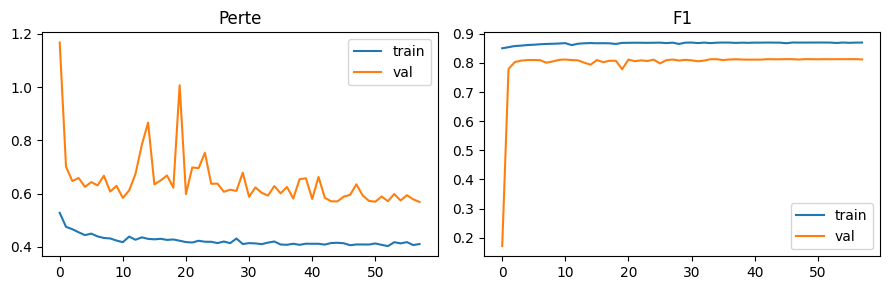

In [10]:
# [6] Modèle : U-Net à encodeur ResNet50 (ImageNet) + perte / métrique masquées
def conv_block(x, f, drop=0.0):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    return layers.SpatialDropout2D(drop)(x) if drop else x

def build_resnet_unet(n_ch=N_CH):
    """Entrée SAR 4 canaux -> conv 1x1 (4->3) -> ResNet50 ImageNet (encodeur) -> décodeur U-Net.
    Entrées de taille libre, multiple de 32 (256 en entraînement, 320 en inférence)."""
    inp = layers.Input((None, None, n_ch))
    stem = layers.BatchNormalization()(layers.Conv2D(3, 1, padding="same", name="sar_to_3ch")(inp))
    base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(None, None, 3))
    names = ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out", "conv5_block3_out"]
    enc = keras.Model(base.input, [base.get_layer(n).output for n in names], name="resnet50_encoder")
    c1, c2, c3, c4, c5 = enc(stem)
    x = c5
    for f, s in zip([256, 128, 64, 32], [c4, c3, c2, c1]):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same")(x)
        x = conv_block(layers.Concatenate()([x, s]), f, 0.1 if f >= 128 else 0)
    x = layers.Conv2DTranspose(16, 2, strides=2, padding="same")(x)
    x = conv_block(layers.Concatenate()([x, inp]), 16)
    return keras.Model(inp, layers.Conv2D(1, 1, activation="sigmoid")(x), name="resnet50_unet_sar"), enc

def build_unet_scratch(n_ch=N_CH, base=32):
    inp = layers.Input((None, None, n_ch)); skips, x = [], inp
    for k, f in enumerate([base, base * 2, base * 4, base * 8]):
        x = conv_block(x, f, 0.1 if k > 1 else 0); skips.append(x); x = layers.MaxPool2D()(x)
    x = conv_block(x, base * 16, 0.3)
    for f, s in zip([base * 8, base * 4, base * 2, base], reversed(skips)):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same")(x)
        x = conv_block(layers.Concatenate()([x, s]), f)
    return keras.Model(inp, layers.Conv2D(1, 1, activation="sigmoid")(x), name="unet_sar"), None

def masked_bce_dice(y_true, y_pred):
    lab, val = y_true[..., 0:1], y_true[..., 1:2]
    p = tf.clip_by_value(y_pred, 1e-6, 1 - 1e-6)
    bce = -(lab * tf.math.log(p) + (1 - lab) * tf.math.log(1 - p))
    bce = tf.reduce_sum(bce * val) / (tf.reduce_sum(val) + 1e-6)
    inter = tf.reduce_sum(p * lab * val)
    return bce + 1 - (2 * inter + 1) / (tf.reduce_sum(p * val) + tf.reduce_sum(lab * val) + 1)

class MaskedF1(keras.metrics.Metric):
    def __init__(self, threshold=0.5, name="f1", **kw):
        super().__init__(name=name, **kw); self.t = threshold
        self.tp = self.add_weight(name="tp", shape=(), initializer="zeros")
        self.fp = self.add_weight(name="fp", shape=(), initializer="zeros")
        self.fn = self.add_weight(name="fn", shape=(), initializer="zeros")
    def update_state(self, y_true, y_pred, sample_weight=None):
        lab, val = y_true[..., 0:1], y_true[..., 1:2]; pred = tf.cast(y_pred > self.t, tf.float32)
        self.tp.assign_add(tf.reduce_sum(pred * lab * val))
        self.fp.assign_add(tf.reduce_sum(pred * (1 - lab) * val))
        self.fn.assign_add(tf.reduce_sum((1 - pred) * lab * val))
    def result(self): return 2 * self.tp / (2 * self.tp + self.fp + self.fn + 1e-7)
    def reset_state(self):
        for v in (self.tp, self.fp, self.fn): v.assign(0.0)

def set_encoder_trainable(enc, flag):
    enc.trainable = flag
    for l in enc.layers:                      # BN de l'encodeur toujours gelées (petit jeu de données)
        if isinstance(l, layers.BatchNormalization): l.trainable = False

def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=masked_bce_dice, metrics=[MaskedF1()])

model, enc = build_resnet_unet() if USE_PRETRAINED else build_unet_scratch()
model.summary(line_length=100, print_fn=lambda s: None)

# Étape 1 : encodeur gelé (le décodeur et la conv 4->3 apprennent d'abord)
if enc is not None: set_encoder_trainable(enc, False)
compile_model(model, 1e-3)
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_STAGE1, callbacks=[
    keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=5, restore_best_weights=True)])

# Étape 2 : fine-tuning complet, petit pas d'apprentissage
if enc is not None: set_encoder_trainable(enc, True)
compile_model(model, 1e-4)
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_STAGE2, callbacks=[
    keras.callbacks.ModelCheckpoint(CKPT, monitor="val_f1", mode="max", save_best_only=True,
                                    initial_value_threshold=max(h1.history["val_f1"])),
    keras.callbacks.ReduceLROnPlateau(monitor="val_f1", mode="max", factor=0.5, patience=4, min_lr=1e-6),
    keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=12, restore_best_weights=True)])
if not os.path.exists(CKPT): model.save(CKPT)           # si l'étape 2 n'a pas amélioré l'étape 1

hist = {k: h1.history[k] + h2.history[k] for k in ("loss", "val_loss", "f1", "val_f1")}
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.plot(hist["loss"], label="train"); plt.plot(hist["val_loss"], label="val"); plt.title("Perte"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(hist["f1"], label="train"); plt.plot(hist["val_f1"], label="val"); plt.title("F1"); plt.legend()
plt.tight_layout(); plt.show()


Seuil optimal : 0.48 | VAL : {'F1': 0.813, 'IoU': 0.685, 'precision': 0.6937, 'recall': 0.982}
TEST GLOBAL       {'F1': 0.9275, 'IoU': 0.8648, 'precision': 0.8682, 'recall': 0.9956}
TEST Grand_Lahou  {'F1': 0.9568, 'IoU': 0.9172, 'precision': 0.9213, 'recall': 0.9951}
TEST Lac_Buyo     {'F1': 0.8642, 'IoU': 0.7609, 'precision': 0.7628, 'recall': 0.9967}


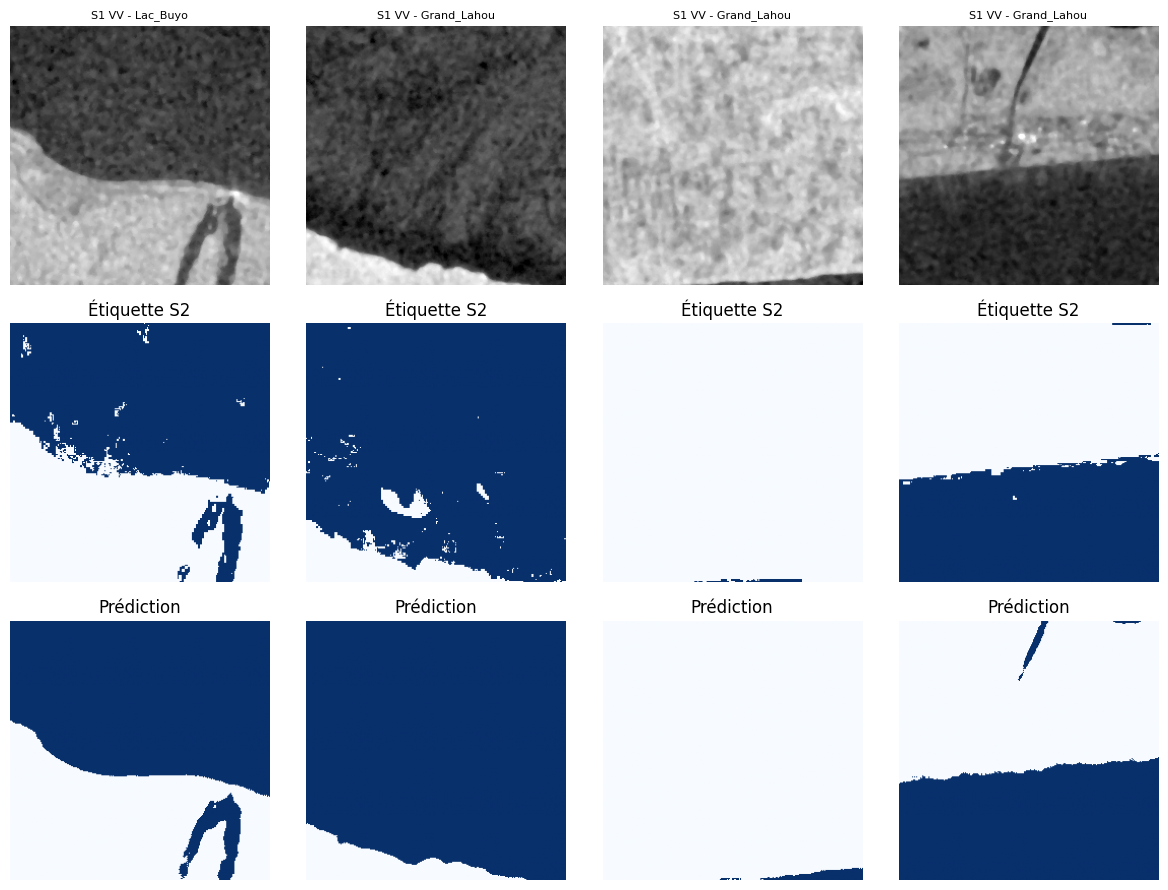

In [11]:
# [7] Seuil optimal (validation) puis évaluation sur zones jamais vues
def predict_np(m, x, bs=8):
    return np.concatenate([m.predict(x[i:i + bs].astype(np.float32), verbose=0) for i in range(0, len(x), bs)])

def scores(y, prob, thr):
    lab, val = y[..., 0:1] > 0, y[..., 1:2] > 0; pred = prob > thr
    tp = (pred & lab & val).sum(); fp = (pred & ~lab & val).sum(); fn = (~pred & lab & val).sum()
    p, r = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return {"F1": float(2 * p * r / (p + r + 1e-9)), "IoU": float(tp / (tp + fp + fn + 1e-9)),
            "precision": float(p), "recall": float(r)}

pva = predict_np(model, Xva)
thrs = np.arange(0.3, 0.71, 0.02)
best_thr = float(thrs[np.argmax([scores(Yva, pva, t)["F1"] for t in thrs])])
print("Seuil optimal :", round(best_thr, 2), "| VAL :", {k: round(v, 4) for k, v in scores(Yva, pva, best_thr).items()})

pte = predict_np(model, Xte) if len(Xte) else None
report = {"threshold": best_thr, "val": scores(Yva, pva, best_thr), "test": {}}
if pte is not None:
    report["test"]["GLOBAL"] = scores(Yte, pte, best_thr)
    for n in TEST_AOIS:
        m = Ate == n
        if m.any(): report["test"][n] = scores(Yte[m], pte[m], best_thr)
    for n, s in report["test"].items():
        print(f"TEST {n:12s}", {k: round(v, 4) for k, v in s.items()})
json.dump(report, open(META, "w"), indent=2)

if pte is not None:
    fig, ax = plt.subplots(3, 4, figsize=(12, 9))
    for r, k in enumerate(np.random.choice(len(Xte), 4, replace=False)):
        ax[0, r].imshow(Xte[k][..., 0].astype(np.float32), cmap="gray"); ax[0, r].set_title(f"S1 VV - {Ate[k]}", fontsize=8)
        ax[1, r].imshow(Yte[k][..., 0], cmap="Blues"); ax[1, r].set_title("Étiquette S2")
        ax[2, r].imshow(pte[k][..., 0] > best_thr, cmap="Blues"); ax[2, r].set_title("Prédiction")
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()


In [12]:
# [8] Quasi temps réel : dernières scènes S1 sur une zone ivoirienne
def near_real_time(zone="Ebrie_Abidjan", days_back=12, core=256, margin=32):
    """`zone` : nom dans AOIS ou emprise (lon_min, lat_min, lon_max, lat_max).
    Produit un GeoTIFF binaire (1 = eau), calcule la surface et l'ajoute au journal CSV.
    Latence ≈ disponibilité des GRD dans GEE (de quelques heures à ~2 jours après l'acquisition ; revisite ≈ 6-12 j)."""
    bbox = AOIS[zone] if isinstance(zone, str) else zone
    tag = zone if isinstance(zone, str) else "custom"
    epsg = epsg_for(bbox)
    mdl = keras.models.load_model(CKPT, custom_objects={"masked_bce_dice": masked_bce_dice, "MaskedF1": MaskedF1})
    thr = json.load(open(META))["threshold"]
    end = dt.date.today() + dt.timedelta(days=1); start = end - dt.timedelta(days=days_back)
    geom = ee.Geometry.Rectangle(bbox)
    n = ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(geom).filterDate(str(start), str(end)).size().getInfo()
    if n == 0: raise RuntimeError("Aucune scène S1 : augmenter days_back.")
    feats, valid = s1_features(geom, str(start), str(end))
    img = ee.Image.cat([feats, valid]).toFloat()

    xmin, ymin, xmax, ymax = bbox_utm(bbox, epsg)
    step = core * SCALE; nx, ny = int((xmax - xmin) // step), int((ymax - ymin) // step); full = core + 2 * margin
    mosaic = np.zeros((ny * core, nx * core), np.uint8); ok = np.zeros_like(mosaic)

    def job(ij):
        i, j = ij
        a = fetch(img, xmin + i * step - margin * SCALE, ymax - j * step + margin * SCALE, full, full, epsg)
        p = mdl.predict(a[None, ..., :4], verbose=0)[0, ..., 0]; c = slice(margin, margin + core)
        return i, j, (p[c, c] > thr).astype(np.uint8), (a[c, c, 4] > 0.5).astype(np.uint8)

    with ThreadPoolExecutor(4) as ex:
        for i, j, m, v in ex.map(job, [(i, j) for j in range(ny) for i in range(nx)]):
            mosaic[j * core:(j + 1) * core, i * core:(i + 1) * core] = m
            ok[j * core:(j + 1) * core, i * core:(i + 1) * core] = v
    mosaic *= ok                                       # rien là où S1 manque

    out_tif = os.path.join(OUT_DIR, f"eau_{tag}_{end}.tif")
    with rasterio.open(out_tif, "w", driver="GTiff", height=mosaic.shape[0], width=mosaic.shape[1], count=1,
                       dtype="uint8", crs=f"EPSG:{epsg}", transform=from_origin(xmin, ymax, SCALE, SCALE),
                       compress="lzw") as dst:
        dst.write(mosaic, 1)
    area = float(mosaic.sum() * SCALE ** 2 / 1e6)
    log = os.path.join(OUT_DIR, "journal_surface_eau.csv"); new = not os.path.exists(log)
    with open(log, "a", newline="") as f:
        w = csv.writer(f)
        if new: w.writerow(["date_run", "zone", "debut", "fin", "n_scenes", "surface_eau_km2", "fichier"])
        w.writerow([dt.date.today(), tag, start, end, n, round(area, 3), out_tif])
    print(f"{tag}: {n} scène(s) S1 | {start} -> {end} | eau = {area:.2f} km² | {out_tif}")
    plt.figure(figsize=(8, 6)); plt.imshow(mosaic, cmap="Blues"); plt.axis("off")
    plt.title(f"Eau de surface S1 - {tag} ({start} → {end})"); plt.show()
    return mosaic


In [ ]:

# mask = near_real_time("Lac_Kossou")
# for z in ["Ebrie_Abidjan", "Lac_Kossou", "Lac_Buyo", "Korhogo_nord"]: near_real_time(z)

# %% [9] Notes
"""
- Lisez surtout les lignes "TEST Grand_Lahou / Lac_Buyo" : ce sont des zones jamais vues, donc le vrai F1.
  Un F1 val de 0.95 avec un F1 test de 0.80 = surapprentissage au site, pas un bon modèle.
- Cas difficiles en Côte d'Ivoire : mangroves et végétation inondée (rétrodiffusion forte, "double bounce"),
  jacinthe d'eau en lagune, rizières inondées au nord, eau turbide ou à vent fort (surface rugueuse = moins sombre en SAR).
- Pour viser 0.92 : numériser ou corriger à la main 50-100 tuiles (surtout lagunes, bas-fonds, rizières), puis
  fine-tuner dessus. Les étiquettes MNDWI sont "faibles" et limitent le F1 mesurable.
- Plus de zones = meilleure généralisation (Comoé, Cavally, Sassandra, lagune de Grand-Bassam, Lac de Kossou nord).
- Les emprises des AOIS sont approximatives : affichez-les avec geemap avant de lancer l'extraction.
- Temps réel : Colab n'est pas un service permanent. Pour automatiser, utilisez le modèle sauvegardé dans un job
  planifié (Cloud Run / GitHub Actions) déclenché toutes les ~6 jours.
"""
